In [1]:
import os
import glob
import pandas as pd

def get_max_accuracy(file_path):
    """读取 CSV 文件并返回最高的 accuracy 值"""
    try:
        # 打开文件查找包含 'accuracy' 列名的行号
        with open(file_path, 'r', encoding='utf-8') as f:
            lines = f.readlines()
        
        header_idx = None
        for idx, line in enumerate(lines):
            # 将行拆分为字段，判断是否存在 'accuracy'
            cols = [col.strip() for col in line.split(',')]
            if 'accuracy' in cols:
                header_idx = idx
                break
        
        # 根据表头位置读取 CSV
        if header_idx is not None:
            df = pd.read_csv(file_path, skiprows=header_idx)
        else:
            df = pd.read_csv(file_path)
        
        # 确保 accuracy 列转换为数值类型
        if 'accuracy' in df.columns:
            df['accuracy'] = pd.to_numeric(df['accuracy'], errors='coerce')
            max_acc = df['accuracy'].max()
            return max_acc
        else:
            return "未找到 accuracy 列"
            
    except Exception as e:
        return f"读取出错: {e}"

def process_folder(folder_path):
    """遍历文件夹下的所有 CSV 文件并输出文件名和最高 accuracy"""
    # 获取文件夹中所有的 csv 文件路径
    csv_files = sorted(glob.glob(os.path.join(folder_path, "*.csv")))
    
    if not csv_files:
        print(f"在目录 '{folder_path}' 中未找到任何 CSV 文件。")
        return

    print(f"{'文件名':<30} | {'最高 Accuracy'}")
    print("-" * 50)
    
    for file_path in csv_files:
        filename = os.path.basename(file_path)
        max_acc = get_max_accuracy(file_path)
        
        # 格式化输出
        if isinstance(max_acc, (int, float)):
            print(f"{filename:<30} | {max_acc:.4f}")
        else:
            print(f"{filename:<30} | {max_acc}")

if __name__ == '__main__':
    # 将此处的路径替换为您的文件夹路径，例如 'dirichlet_0_1_10' 或 './'
    folder_directory = "./"  
    
    process_folder(folder_directory)

文件名                            | 最高 Accuracy
--------------------------------------------------
fmnist_fedss_01_epoch10.csv    | 0.7857
fmnist_fedss_02_epoch10.csv    | 0.7931
fmnist_fedss_03_epoch10.csv    | 0.7824
fmnist_fedss_04_epoch10.csv    | 0.7787
fmnist_fedss_05_epoch10.csv    | 0.7846
fmnist_fedss_06_epoch10.csv    | 0.7823
fmnist_fedss_07_epoch10.csv    | 0.7823
fmnist_fedss_08_epoch10.csv    | 0.7899
fmnist_fedss_09_epoch10.csv    | 0.7811
fmnist_fedss_10_epoch10.csv    | 0.7855


文件名                                 | FedSS 参数     | 最高 Accuracy
-----------------------------------------------------------------
fmnist_fedss_01_epoch10.csv         | 0.1          | 0.7857
fmnist_fedss_02_epoch10.csv         | 0.2          | 0.7931
fmnist_fedss_03_epoch10.csv         | 0.3          | 0.7824
fmnist_fedss_04_epoch10.csv         | 0.4          | 0.7787
fmnist_fedss_05_epoch10.csv         | 0.5          | 0.7846
fmnist_fedss_06_epoch10.csv         | 0.6          | 0.7823
fmnist_fedss_07_epoch10.csv         | 0.7          | 0.7823
fmnist_fedss_08_epoch10.csv         | 0.8          | 0.7899
fmnist_fedss_09_epoch10.csv         | 0.9          | 0.7811
fmnist_fedss_10_epoch10.csv         | 1.0          | 0.7855


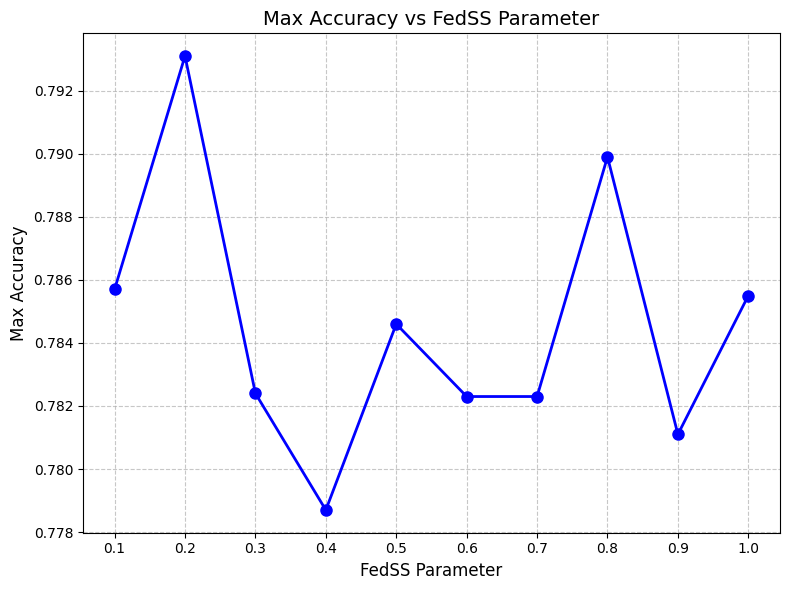

In [3]:
import os
import glob
import pandas as pd
import re
import matplotlib.pyplot as plt

def get_max_accuracy(file_path):
    """读取 CSV 文件并返回最高的 accuracy 值"""
    try:
        # 打开文件查找包含 'accuracy' 列名的行号
        with open(file_path, 'r', encoding='utf-8') as f:
            lines = f.readlines()
        
        header_idx = None
        for idx, line in enumerate(lines):
            # 将行拆分为字段，判断是否存在 'accuracy'
            cols = [col.strip() for col in line.split(',')]
            if 'accuracy' in cols:
                header_idx = idx
                break
        
        # 根据表头位置读取 CSV
        if header_idx is not None:
            df = pd.read_csv(file_path, skiprows=header_idx)
        else:
            df = pd.read_csv(file_path)
        
        # 确保 accuracy 列转换为数值类型
        if 'accuracy' in df.columns:
            df['accuracy'] = pd.to_numeric(df['accuracy'], errors='coerce')
            max_acc = df['accuracy'].max()
            return max_acc
        else:
            return "未找到 accuracy 列"
            
    except Exception as e:
        return f"读取出错: {e}"

def process_folder_and_plot(folder_path):
    """遍历文件夹下的特定 CSV 文件，提取精度并绘制折线图"""
    # 获取文件夹中所有的 csv 文件路径
    csv_files = glob.glob(os.path.join(folder_path, "*.csv"))
    
    if not csv_files:
        print(f"在目录 '{folder_path}' 中未找到任何 CSV 文件。")
        return

    # 用于存储 (fedss参数, 最高精度) 的列表
    data_points = []

    print(f"{'文件名':<35} | {'FedSS 参数':<12} | {'最高 Accuracy'}")
    print("-" * 65)
    
    for file_path in csv_files:
        filename = os.path.basename(file_path)
        
        # 使用正则表达式匹配文件名中的 fedss 参数，例如 'fedss_01'
        match = re.search(r'fedss_(\d+)', filename)
        if match:
            # 提取数字（例如 '01' 变成 1），然后除以 10 得到 0.1 到 1.0
            fedss_param = int(match.group(1)) / 10.0
            
            # 获取最高精度
            max_acc = get_max_accuracy(file_path)
            
            # 只有当精度成功读取且为数值时才记录
            if isinstance(max_acc, (int, float)):
                data_points.append((fedss_param, max_acc))
                print(f"{filename:<35} | {fedss_param:<12.1f} | {max_acc:.4f}")
            else:
                print(f"{filename:<35} | {fedss_param:<12.1f} | {max_acc}")

    # 如果提取到了有效数据，则开始画图
    if data_points:
        # 按 fedss 参数 (横坐标) 从小到大排序，防止折线图连线混乱
        data_points.sort(key=lambda x: x[0])
        
        # 解压数据，分别得到 x 和 y 的列表
        x_vals = [point[0] for point in data_points]
        y_vals = [point[1] for point in data_points]

        #print(x_vals)
        #print(y_vals)
        # 绘制折线图
        plt.figure(figsize=(8, 6))
        plt.plot(x_vals, y_vals, marker='o', linestyle='-', color='b', linewidth=2, markersize=8)
        
        # 设置图表标题和坐标轴标签
        plt.title('Max Accuracy vs FedSS Parameter', fontsize=14)
        plt.xlabel('FedSS Parameter', fontsize=12)
        plt.ylabel('Max Accuracy', fontsize=12)


        #plt.ylim(0.1, 0.7)
        # 设置 x 轴刻度，使其正好对应 0.1, 0.2, ... 1.0
        plt.xticks(x_vals)
        
        # 显示网格
        plt.grid(True, linestyle='--', alpha=0.7)
        
        # 调整布局并显示
        plt.tight_layout()
        plt.show()
    else:
        print("没有成功提取到可以用于绘图的准确率数据。请检查文件名格式或 CSV 内容。")

if __name__ == '__main__':
    # 将此处的路径替换为您的文件夹路径
    folder_directory = "./"  
    
    process_folder_and_plot(folder_directory)

文件名                                 | FedSS 参数     | 最高 Accuracy
-----------------------------------------------------------------
fmnist_fedss_01_epoch10.csv         | 0.01         | 0.7857
fmnist_fedss_02_epoch10.csv         | 0.02         | 0.7931
fmnist_fedss_03_epoch10.csv         | 0.03         | 0.7824
fmnist_fedss_04_epoch10.csv         | 0.04         | 0.7787
fmnist_fedss_05_epoch10.csv         | 0.05         | 0.7846
fmnist_fedss_06_epoch10.csv         | 0.06         | 0.7823
fmnist_fedss_07_epoch10.csv         | 0.07         | 0.7823
fmnist_fedss_08_epoch10.csv         | 0.08         | 0.7899
fmnist_fedss_09_epoch10.csv         | 0.09         | 0.7811
fmnist_fedss_10_epoch10.csv         | 0.10         | 0.7855


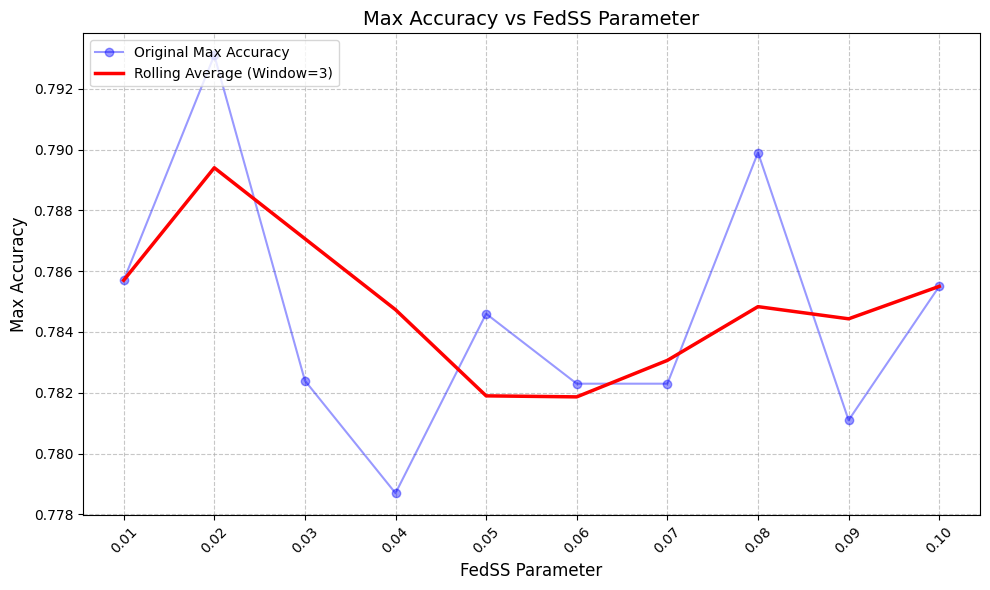

In [4]:
import os
import glob
import pandas as pd
import re
import matplotlib.pyplot as plt

def get_max_accuracy(file_path):
    """读取 CSV 文件并返回最高的 accuracy 值"""
    try:
        # 打开文件查找包含 'accuracy' 列名的行号
        with open(file_path, 'r', encoding='utf-8') as f:
            lines = f.readlines()
        
        header_idx = None
        for idx, line in enumerate(lines):
            # 将行拆分为字段，判断是否存在 'accuracy'
            cols = [col.strip() for col in line.split(',')]
            if 'accuracy' in cols:
                header_idx = idx
                break
        
        # 根据表头位置读取 CSV
        if header_idx is not None:
            df = pd.read_csv(file_path, skiprows=header_idx)
        else:
            df = pd.read_csv(file_path)
        
        # 确保 accuracy 列转换为数值类型
        if 'accuracy' in df.columns:
            df['accuracy'] = pd.to_numeric(df['accuracy'], errors='coerce')
            max_acc = df['accuracy'].max()
            return max_acc
        else:
            return "未找到 accuracy 列"
            
    except Exception as e:
        return f"读取出错: {e}"

def process_folder_and_plot(folder_path):
    """遍历文件夹下的特定 CSV 文件，提取精度并绘制折线图和滑动平均图"""
    # 获取文件夹中所有的 csv 文件路径
    csv_files = glob.glob(os.path.join(folder_path, "*.csv"))
    
    if not csv_files:
        print(f"在目录 '{folder_path}' 中未找到任何 CSV 文件。")
        return

    # 用于存储 (fedss参数, 最高精度) 的列表
    data_points = []

    print(f"{'文件名':<35} | {'FedSS 参数':<12} | {'最高 Accuracy'}")
    print("-" * 65)
    
    for file_path in csv_files:
        filename = os.path.basename(file_path)
        
        # 使用正则表达式匹配文件名中的 fedss 参数
        match = re.search(r'fedss_(\d+)', filename)
        if match:
            # 提取数字（例如 '01' 变成 1），然后除以 100 得到 0.01 到 0.10 (根据您的当前代码逻辑)
            fedss_param = int(match.group(1)) / 100.0
            
            # 获取最高精度
            max_acc = get_max_accuracy(file_path)
            
            # 只有当精度成功读取且为数值时才记录
            if isinstance(max_acc, (int, float)):
                data_points.append((fedss_param, max_acc))
                print(f"{filename:<35} | {fedss_param:<12.2f} | {max_acc:.4f}")
            else:
                print(f"{filename:<35} | {fedss_param:<12.2f} | {max_acc}")

    # 如果提取到了有效数据，则开始画图
    if data_points:
        # 按 fedss 参数 (横坐标) 从小到大排序
        data_points.sort(key=lambda x: x[0])
        
        # 解压数据，分别得到 x 和 y 的列表
        x_vals = [point[0] for point in data_points]
        y_vals = [point[1] for point in data_points]
        
        # 计算滑动平均 (Rolling Average)
        # window=3 代表过去3个点的平均。min_periods=1 保证最前面的点也能计算平均而不是留空 (NaN)
        window_size = 3
        y_rolling_avg = pd.Series(y_vals).rolling(window=window_size, min_periods=1).mean()
        
        # 创建画布，宽度稍微调大一些以适应较多的 X 轴标签
        plt.figure(figsize=(10, 6))
        
        # 1. 绘制原始数据的折线图 (稍微降低透明度 alpha，突出滑动平均线)
        plt.plot(x_vals, y_vals, marker='o', linestyle='-', color='b', linewidth=1.5, markersize=6, alpha=0.4, label='Original Max Accuracy')
        
        # 2. 绘制滑动平均曲线
        plt.plot(x_vals, y_rolling_avg, linestyle='-', color='red', linewidth=2.5, label=f'Rolling Average (Window={window_size})')
        
        # 设置图表标题和坐标轴标签
        plt.title('Max Accuracy vs FedSS Parameter', fontsize=14)
        plt.xlabel('FedSS Parameter', fontsize=12)
        plt.ylabel('Max Accuracy', fontsize=12)
        
        # 设置 Y 轴的范围 (0.1 到 0.7)
        # plt.ylim(0.1, 0.7)
        
        # 设置 x 轴刻度，由于点可能比较多，加上 45 度旋转防止数字重叠
        plt.xticks(x_vals, rotation=45)
        
        # 显示网格
        plt.grid(True, linestyle='--', alpha=0.7)
        
        # 添加图例
        plt.legend(loc='upper left', fontsize=10)
        
        # 调整布局并显示
        plt.tight_layout()
        plt.show()
    else:
        print("没有成功提取到可以用于绘图的准确率数据。请检查文件名格式或 CSV 内容。")

if __name__ == '__main__':
    # 将此处的路径替换为您的文件夹路径
    folder_directory = "./"  
    
    process_folder_and_plot(folder_directory)